# Otimização do Random Forest – Passo 5: variáveis novas (abordagem B, 1 min × 12 meses)

**Por que agora:** os passos 3 e 4 mostraram que nem o cenário nem a regra de saída criam vantagem: o ganho bruto
máximo fica em ~3 pts por operação, abaixo do custo de 5. O gargalo é o **sinal**. As 16 variáveis atuais só
enxergam os últimos 10 minutos; as mais usadas são do próprio minuto t (corpo e último retorno).

**Hipótese:** contexto mais longo ajuda o modelo a reconhecer situações em que o próximo minuto tende a andar mais
que o custo em uma direção.

| Grupo | Variáveis | Intuição |
|---|---|---|
| **Multiescala** | retorno acumulado em 5/15/30/60 min; volatilidade em 15/60 min; volume relativo de 15 min; amplitude média de 15 min | Tendência ou reversão de prazo maior; regime de volatilidade recente |
| **Estrutura do dia** | distância da VWAP do dia; posição no intervalo máxima–mínima do dia; distância da máxima e da mínima do dia; retorno desde a abertura; gap de abertura | Onde o preço está em relação ao próprio pregão (suportes e resistências intradiárias) |

Todas são conhecidas no fechamento do minuto t (o notebook verifica que apagar o futuro não muda o valor).

**Variantes:** base (16 variáveis), base + multiescala, base + estrutura do dia, base + todas. Mesma floresta
(`rf_d4_f2`), mesmo corte de classes, mesmo calendário. Só validação (2024).

**Critério registrado:** candidata = configuração (variante × regra × limiar) com esperança > 0, t ≥ 2 e ≥ 3
trimestres positivos → vence o maior retorno sobre capital. Sem candidatas → vence a variante com **maior t do ganho
bruto** (o mesmo desempate dos passos 2 e 4).

In [1]:
import os, sys, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

sys.path.append(PASTA)
sys.path.append(f"{PASTA}/frentes/ml")
import tt1_comum as t
import otim_rf as o

SAIDA = f"{PASTA}/resultados/ml/otimizacao"
D4 = json.load(open(f"{SAIDA}/decisao_passo4.json", encoding="utf-8"))
CANDLE, JANELA = D4["candle"], D4["janela_meses"]
BASE = t.features()["COMPLETO"]
VARIANTES = {"base": BASE,
             "base+multiescala": BASE + o.GRUPOS_NOVOS["multiescala"],
             "base+estrutura_dia": BASE + o.GRUPOS_NOVOS["estrutura_dia"],
             "base+todas": BASE + o.GRUPOS_NOVOS["multiescala"] + o.GRUPOS_NOVOS["estrutura_dia"]}
json.dump(dict(passo="5 - variáveis", candle=CANDLE, janela_meses=JANELA,
               variantes={k: v for k, v in VARIANTES.items()}, floresta=o.RF_PADRAO,
               criterio_candidata=f"esperança > 0, t ≥ {o.T_MIN}, ≥ {o.TRIM_MIN} trimestres positivos",
               criterio_sem_candidatas="maior t do ganho bruto"),
          open(f"{SAIDA}/registro_passo5.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
df, _ = t.montar_base(win, wdo, CANDLE)
DF = o.rotular(o.adicionar_features(df))     # mesma base (mesmas linhas) para todas as variantes

# verificação de vazamento: o valor em t não muda se o futuro for apagado
corte = DF.index[len(DF) // 2]
parcial = o.adicionar_features(df[df.index <= corte])
novas = sum(o.GRUPOS_NOVOS.values(), [])
assert np.allclose(parcial.loc[corte, novas].astype(float), DF.loc[corte, novas].astype(float))
print(f"{len(DF):,} candles | {len(novas)} variáveis novas | sem vazamento")

686,124 candles | 14 variáveis novas | sem vazamento


In [2]:
qual, regras = [], []
for nome, feats in VARIANTES.items():
    t0 = time.time()
    prev, _ = o.walk_forward_b(DF, feats, *t.VALIDACAO, janela_meses=JANELA)
    prev.to_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_rfB_{nome}_val.csv")
    g = o.grade_regras(prev).assign(variante=nome)
    regras.append(g)
    m = g[g.serie == "modelo"]
    best = m.sort_values("esperanca_pts", ascending=False).iloc[0]
    qual.append(dict(variante=nome, n_variaveis=len(feats), tempo_s=round(time.time() - t0, 1), **o.qualidade(prev),
                     melhor_regra=best.regra, melhor_limiar_q=best.limiar_q, melhor_esperanca=best.esperanca_pts,
                     melhor_t=best.t_stat, melhor_bruto=best.bruto_pts, melhor_trim_pos=best.trimestres_positivos,
                     n_candidatas=int(g.candidata.sum())))
    q = qual[-1]
    print(f"{nome:>20}: Spearman {q['spearman']:+.4f} | bruto {q['bruto_esperanca_pts']:+.2f} pts (t {q['bruto_t_stat']:.2f}) | "
          f"melhor {best.regra} q{best.limiar_q:.0%}: {best.esperanca_pts:+.2f} (t {best.t_stat:.2f}) | {q['tempo_s']}s")
qual = pd.DataFrame(qual)
regras = pd.concat(regras, ignore_index=True)
qual.to_csv(f"{SAIDA}/variaveis_qualidade_val.csv", index=False)
regras.to_csv(f"{SAIDA}/variaveis_regras_val.csv", index=False)
qual.round(4)

                base: Spearman +0.0193 | bruto +0.40 pts (t 3.57) | melhor segurar q75%: -1.87 (t -1.30) | 22.8s


    base+multiescala: Spearman +0.0188 | bruto +0.44 pts (t 3.88) | melhor por_candle q98%: -3.58 (t -4.18) | 31.3s


  base+estrutura_dia: Spearman +0.0191 | bruto +0.36 pts (t 3.24) | melhor segurar q75%: -2.53 (t -1.67) | 36.1s


          base+todas: Spearman +0.0192 | bruto +0.47 pts (t 4.18) | melhor por_candle q98%: -2.67 (t -3.13) | 73.6s


,variante,n_variaveis,tempo_s,spearman,acc_dir,bruto_n_ops,bruto_esperanca_pts,bruto_ep_pts,bruto_t_stat,melhor_regra,melhor_limiar_q,melhor_esperanca,melhor_t,melhor_bruto,melhor_trim_pos,n_candidatas
0,base,16,22.8,0.0193,0.5117,141216,0.4007,0.1121,3.5747,segurar,0.75,-1.8726,-1.2952,3.1274,2,0
1,base+multiescala,24,31.3,0.0188,0.5128,141216,0.4354,0.1121,3.8843,por_candle,0.98,-3.5805,-4.1817,1.4195,0,0
2,base+estrutura_dia,22,36.1,0.0191,0.5114,141216,0.3630,0.1121,3.2380,segurar,0.75,-2.5275,-1.6744,2.4725,1,0
3,base+todas,30,73.6,0.0192,0.5130,141216,0.4690,0.1121,4.1838,por_candle,0.98,-2.6726,-3.1327,2.3274,1,0


## Ganho bruto por limiar (custo 0), por variante

Se as variáveis novas ajudam, as curvas sobem, principalmente nos limiares altos (os sinais mais fortes).

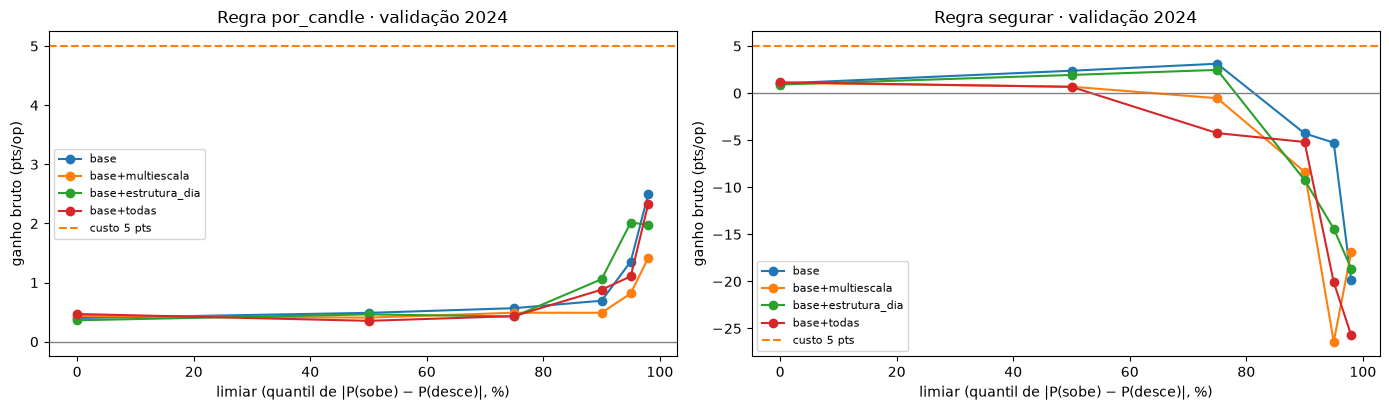

,variante,regra,limiar_q,n_ops,candles_medios,bruto_pts,esperanca_pts,t_stat,lucro_R,trimestres_positivos,candidata
10,base,segurar,0.75,9639,12.759,3.127,-1.873,-1.295,-3610.0,2,False
20,base,por_candle,0.98,2825,1.000,2.496,-2.504,-2.492,-1415.0,0,False
58,base+estrutura_dia,segurar,0.75,8621,12.959,2.472,-2.528,-1.674,-4358.0,1,False
6,base,segurar,0.50,24428,5.770,2.384,-2.616,-3.989,-12781.0,1,False
92,base+todas,por_candle,0.98,2825,1.000,2.327,-2.673,-3.133,-1510.0,1,False
64,base+estrutura_dia,por_candle,0.95,7061,1.000,2.016,-2.984,-5.518,-4214.0,0,False
68,base+estrutura_dia,por_candle,0.98,2825,1.000,1.977,-3.023,-2.967,-1708.0,1,False
54,base+estrutura_dia,segurar,0.50,23697,5.915,1.937,-3.063,-4.582,-14519.0,0,False
44,base+multiescala,por_candle,0.98,2825,1.000,1.419,-3.581,-4.182,-2023.0,0,False
16,base,por_candle,0.95,7061,1.000,1.357,-3.643,-6.662,-5145.0,0,False


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, regra in zip(axes, ["por_candle", "segurar"]):
    for nome in VARIANTES:
        r = regras[(regras.serie == "modelo") & (regras.regra == regra) & (regras.variante == nome)]
        ax.plot(r.limiar_q * 100, r.bruto_pts, "o-", label=nome)
    ax.axhline(o.CUSTO, color="tab:orange", ls="--", label="custo 5 pts"); ax.axhline(0, color="gray", lw=1)
    ax.set_xlabel("limiar (quantil de |P(sobe) − P(desce)|, %)"); ax.set_ylabel("ganho bruto (pts/op)")
    ax.set_title(f"Regra {regra} · validação 2024"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/variaveis_bruto_limiar.png", dpi=150); plt.show()
cols = ["variante", "regra", "limiar_q", "n_ops", "candles_medios", "bruto_pts", "esperanca_pts", "t_stat",
        "lucro_R", "trimestres_positivos", "candidata"]
regras[regras.serie == "modelo"].sort_values("esperanca_pts", ascending=False)[cols].round(3).head(12)

## Decisão do passo 5

In [4]:
cand = regras[regras.candidata].sort_values("retorno_capital", ascending=False)
if len(cand):
    VAR = cand.iloc[0].variante
    CRITERIO = "maior retorno sobre capital entre as candidatas"
else:
    VAR = qual.sort_values("bruto_t_stat", ascending=False).iloc[0].variante
    CRITERIO = "nenhuma candidata: maior t do ganho bruto"
v = qual[qual.variante == VAR].iloc[0]
print("Critério:", CRITERIO)
print(f"Variante escolhida: {VAR} ({v.n_variaveis} variáveis) | Spearman {v.spearman:.4f} | bruto {v.bruto_esperanca_pts:+.2f} "
      f"pts (t {v.bruto_t_stat:.2f}) | melhor regra {v.melhor_regra} q{v.melhor_limiar_q:.0%}: {v.melhor_esperanca:+.2f} (t {v.melhor_t:.2f})")
json.dump(dict(passo="5 - variáveis", criterio=CRITERIO, variante=VAR, variaveis=VARIANTES[VAR],
               n_candidatas=int(len(cand)), spearman=float(v.spearman), bruto_pts=float(v.bruto_esperanca_pts),
               bruto_t=float(v.bruto_t_stat)),
          open(f"{SAIDA}/decisao_passo5.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

Critério: nenhuma candidata: maior t do ganho bruto
Variante escolhida: base+todas (30 variáveis) | Spearman 0.0192 | bruto +0.47 pts (t 4.18) | melhor regra por_candle q98%: -2.67 (t -3.13)


## Importância das variáveis na variante escolhida

Floresta treinada na última janela da validação (out/2023–set/2024). Importância = redução média do Gini.

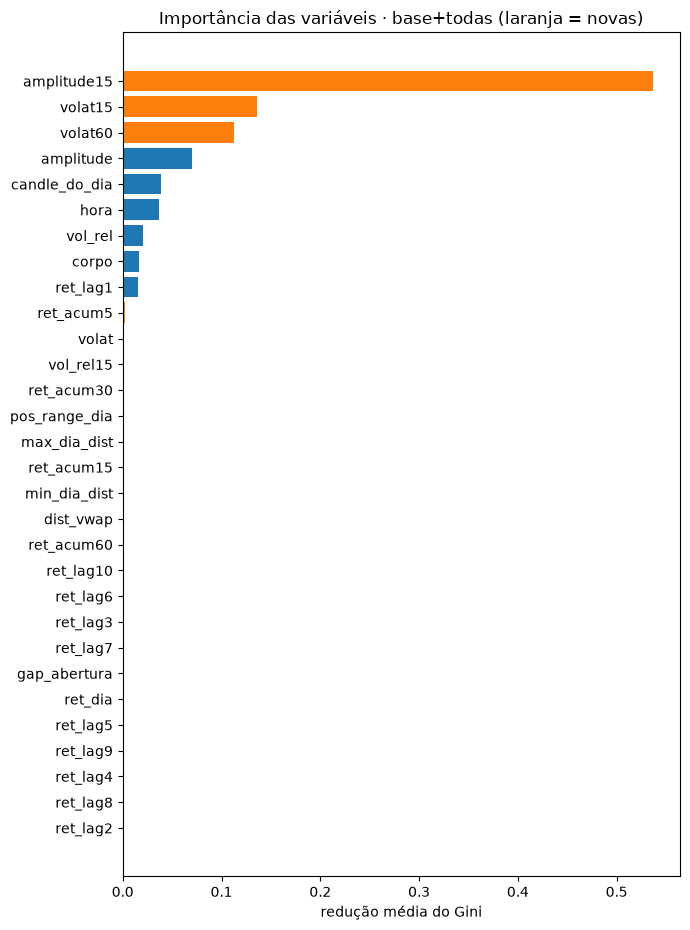

In [5]:
ini = pd.Timestamp("2024-10-01")
tr = DF[(DF.index >= ini - pd.DateOffset(months=JANELA)) & (DF.index < ini)].iloc[:-1]
rf = o.RF_PADRAO
clf = RandomForestClassifier(n_estimators=rf["n_estimators"], max_depth=rf["max_depth"], max_features=rf["max_features"],
                             min_samples_leaf=max(rf["folha_min"], int(rf["folha_frac"] * len(tr))), n_jobs=-1,
                             random_state=42).fit(tr[VARIANTES[VAR]].values, tr.classe.values)
imp = pd.Series(clf.feature_importances_, index=VARIANTES[VAR]).sort_values()
imp.to_csv(f"{SAIDA}/variaveis_importancia.csv", header=["importancia"])
fig, ax = plt.subplots(figsize=(7, 0.28 * len(imp) + 1))
cores = ["tab:orange" if c in novas else "tab:blue" for c in imp.index]
ax.barh(imp.index, imp.values, color=cores)
ax.set_title(f"Importância das variáveis · {VAR} (laranja = novas)"); ax.set_xlabel("redução média do Gini")
fig.tight_layout(); fig.savefig(f"{SAIDA}/variaveis_importancia.png", dpi=150); plt.show()